id: notebooks/C_sampling_iq.ipynb

sampling and complex baseband: Nyquist and aliasing, IQ mixing, IQ imbalance and DC offset, band edges, quantisation (efficiency, Van Vleck, level), what the B210 delivers

<!-- notebooks/C_sampling_iq.ipynb -- theory C: sampling and complex baseband (Interferosim 0.9.2) -->
# C – Sampling and the complex baseband

---
  DI Erich Schubert, 07925151
  


*Theory notebook C.* Every simulated stream of notebooks 03–09 is a sequence of complex samples – "IQ" – as the B210 delivers them. This notebook explains what these numbers are: how a radio band at 1.4 GHz becomes a complex signal around 0 Hz, why a complex sample rate $f_s$ covers a bandwidth $f_s$, what goes wrong when the I and Q branches are not perfect, and how few bits are needed to keep the correlation of two noise signals.

Package functions used: `quantize`, `fractional_delay`, `Accumulator`, the B210 profile (`Receiver`), new in 0.9.2 `iq_imbalance`, `image_rejection_db`, `quantizer_levels`, `quantization_efficiency`, `van_vleck_1bit`.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from interferosim.constants import HI_21CM
from interferosim.instrument import Receiver
from interferosim.signal import (quantize, Accumulator, iq_imbalance, image_rejection_db, quantizer_levels,
                                 quantization_efficiency, van_vleck_1bit)

CFG = Path("..") / "configs"
b210 = Receiver.from_toml(CFG / "receivers" / "b210.toml")
rng = np.random.default_rng(3)

def spectrum_db(x, fs, nfft=1024):
    """Averaged power spectrum in dB (Hann window), frequency axis centred."""
    acc = Accumulator.create(nfft, "hann"); acc.add(x, x)
    p = np.real(acc.visibility()) / acc.window_power
    return acc.freq_axis(fs), 10 * np.log10(np.maximum(p, 1e-30))
print(f"B210 profile: {b210.sample_rate_sps / 1e6:.1f} MS/s complex, bandwidth {b210.bandwidth_hz / 1e6:.1f} MHz, "
      f"{b210.adc_bits}-bit ADC, host format {b210.sample_format}")

B210 profile: 2.0 MS/s complex, bandwidth 2.0 MHz, 12-bit ADC, host format sc16


## 1. Sampling and aliasing

A real signal sampled at the rate $f_s$ is only unambiguous up to $f_s/2$ (**Nyquist**). A component at $f > f_s/2$ produces exactly the same samples as one at $|f - k f_s|$: it is **aliased** into the band. The samples carry no trace of which of the candidates was the original – the analogue filter in front of the ADC has to remove everything outside the band beforehand.

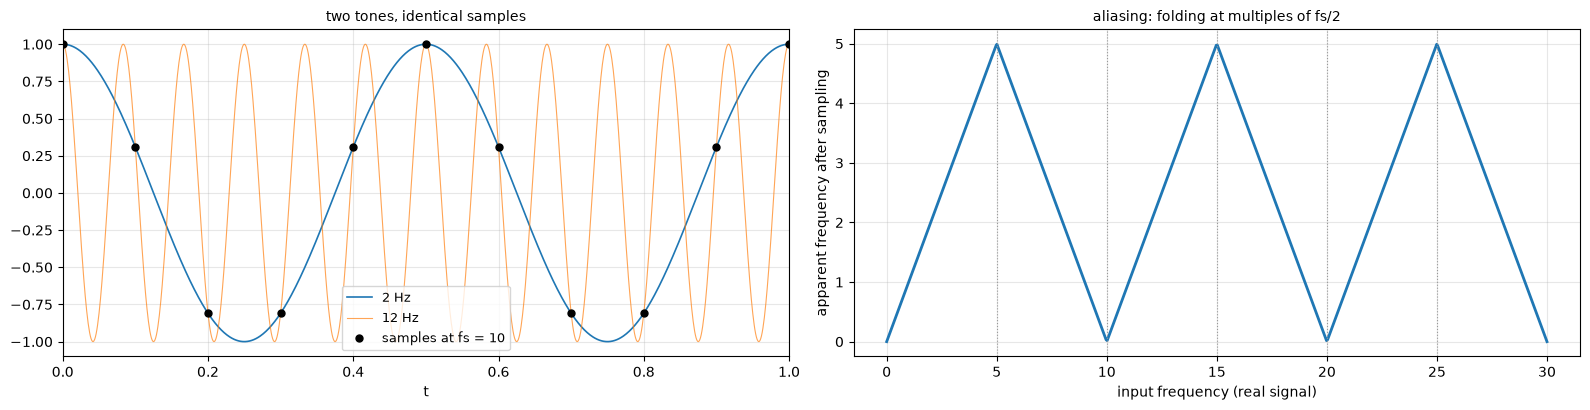

max difference of the samples of 2 Hz and 12 Hz: 1.0e-14


In [2]:
fs = 10.0                                         # samples per unit time (arbitrary units)
t_fine = np.linspace(0, 2, 2001)
t_s = np.arange(0, 2, 1 / fs)
f1, f2 = 2.0, 12.0                                # 12 = 2 + fs: same samples
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
axes[0].plot(t_fine, np.cos(2 * np.pi * f1 * t_fine), lw=1.2, label=f"{f1:g} Hz")
axes[0].plot(t_fine, np.cos(2 * np.pi * f2 * t_fine), lw=0.8, alpha=0.7, label=f"{f2:g} Hz")
axes[0].plot(t_s, np.cos(2 * np.pi * f1 * t_s), "ko", ms=5, label=f"samples at fs = {fs:g}")
axes[0].set(xlabel="t", xlim=(0, 1), title="two tones, identical samples"); axes[0].legend(fontsize=9)
f_in = np.linspace(0, 3 * fs, 600)
f_alias = np.abs(((f_in + fs / 2) % fs) - fs / 2)
axes[1].plot(f_in, f_alias, lw=2)
for k in range(1, 6): axes[1].axvline(k * fs / 2, color="0.6", ls=":", lw=0.8)
axes[1].set(xlabel="input frequency (real signal)", ylabel="apparent frequency after sampling",
            title="aliasing: folding at multiples of fs/2")
for ax in axes: ax.grid(alpha=0.3); ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()
print(f"max difference of the samples of {f1:g} Hz and {f2:g} Hz: {np.max(np.abs(np.cos(2*np.pi*f1*t_s) - np.cos(2*np.pi*f2*t_s))):.1e}")

## 2. From the radio band to the complex baseband

The receiver mixes the RF signal with a local oscillator $f_\mathrm{LO}$ in two branches, with $\cos$ (I) and $-\sin$ (Q), and low-pass filters both:

$$x(t) = I(t) + iQ(t) = \mathrm{LP}\left\{s_\mathrm{RF}(t)\,e^{-2\pi i f_\mathrm{LO} t}\right\}.$$

The band $f_\mathrm{LO} \pm f_s/2$ ends up at $\pm f_s/2$ around 0 Hz, **with the sign kept**: a component above the LO appears at positive, one below at negative frequency. With the real signal alone (only I) the two would fall onto each other. That is why a complex sample rate $f_s$ covers the bandwidth $f_s$ (a real one only $f_s/2$), and why the B210 at 2 MS/s records 2 MHz around 1420.4 MHz. Simulated with a scaled-down RF: a carrier band of noise with two tones 0.3 above and 0.5 below the LO.

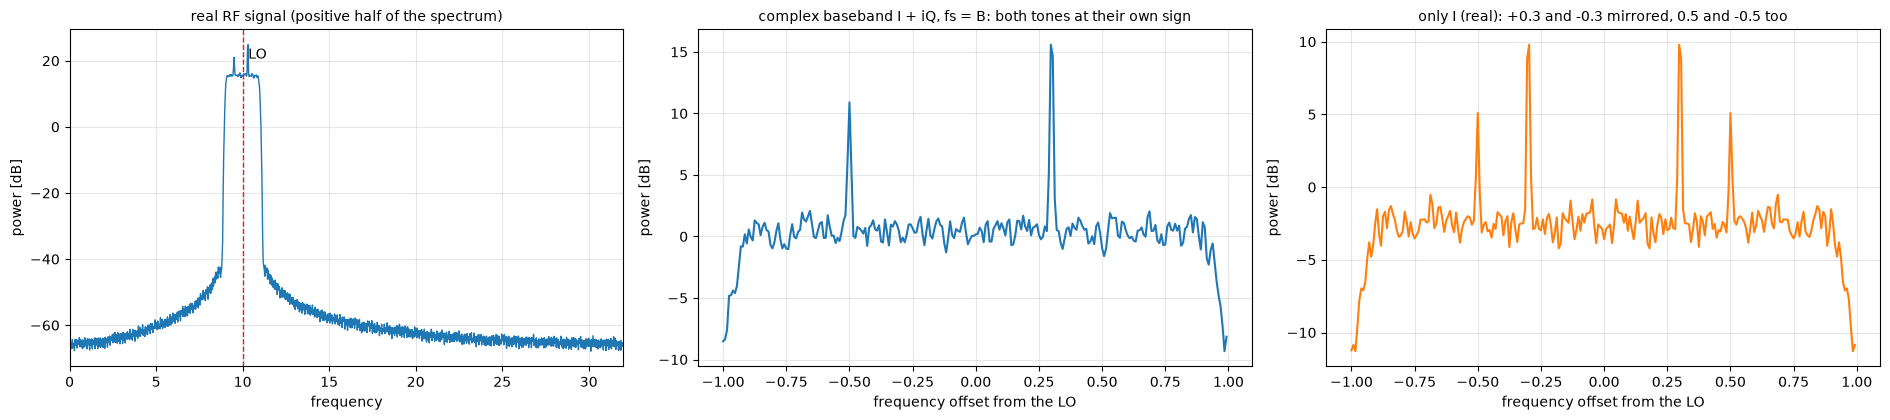

complex baseband: 8192 samples at fs = 2, band -1 ... +1 around the LO


In [3]:
fs_rf, n = 64.0, 2 ** 18                         # "RF" sampled finely (arbitrary units)
t = np.arange(n) / fs_rf
f_lo, B = 10.0, 2.0
noise = rng.standard_normal(n)
from scipy.signal import firwin, lfilter
bp = firwin(801, [f_lo - B / 2, f_lo + B / 2], pass_zero=False, fs=fs_rf)
rf = lfilter(bp, 1.0, noise) * 6 + 1.0 * np.cos(2 * np.pi * (f_lo + 0.3) * t) + 0.5 * np.cos(2 * np.pi * (f_lo - 0.5) * t)
mixed = rf * np.exp(-2j * np.pi * f_lo * t)                      # I = rf cos, Q = -rf sin
lp = firwin(801, B / 2, fs=fs_rf)
bb = lfilter(lp, 1.0, mixed)[::int(fs_rf / B)]                  # low-pass, decimate to fs = B
fig, axes = plt.subplots(1, 3, figsize=(19, 4.3))
f, p = spectrum_db(rf + 0j, fs_rf, 2048); axes[0].plot(f, p, lw=1)
axes[0].set(xlim=(0, fs_rf / 2), title="real RF signal (positive half of the spectrum)", xlabel="frequency")
axes[0].axvline(f_lo, color="C3", ls="--", lw=1); axes[0].annotate("LO", (f_lo, p.max()), xytext=(4, -10), textcoords="offset points")
f, p = spectrum_db(bb, B, 256); axes[1].plot(f, p, lw=1.5)
axes[1].set(title="complex baseband I + iQ, fs = B: both tones at their own sign", xlabel="frequency offset from the LO")
f, p = spectrum_db(bb.real + 0j, B, 256); axes[2].plot(f, p, lw=1.5, color="C1")
axes[2].set(title="only I (real): +0.3 and -0.3 mirrored, 0.5 and -0.5 too", xlabel="frequency offset from the LO")
for ax in axes: ax.set_ylabel("power [dB]"); ax.grid(alpha=0.3); ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()
print(f"complex baseband: {bb.size} samples at fs = {B:g}, band -{B / 2:g} ... +{B / 2:g} around the LO")

## 3. IQ imbalance and DC offset

Real mixers are not perfect: the Q branch has a slightly different gain ($g$) and is not exactly 90° off ($\varphi$). Then a tone at $+f$ produces an **image** at $-f$, suppressed by the image rejection ratio

$$\mathrm{IRR} = \frac{1 + 2g\cos\varphi + g^2}{1 - 2g\cos\varphi + g^2}.$$

A leak of the LO into the signal path gives a **DC offset**: a spike at 0 Hz. Both matter for an interferometer: with two channels on one B210 the LO leakage is *common* to both channels and correlates – a false visibility in the centre channel that does not rotate with the fringe rate (the crosstalk check of notebook 08). The B210 profile switches the automatic DC-offset and IQ-balance corrections **off** (`dc_offset_correction = false`, `iq_balance_correction = false`), because they adapt continuously and would change the gain during the observation; the centre channel is flagged instead.

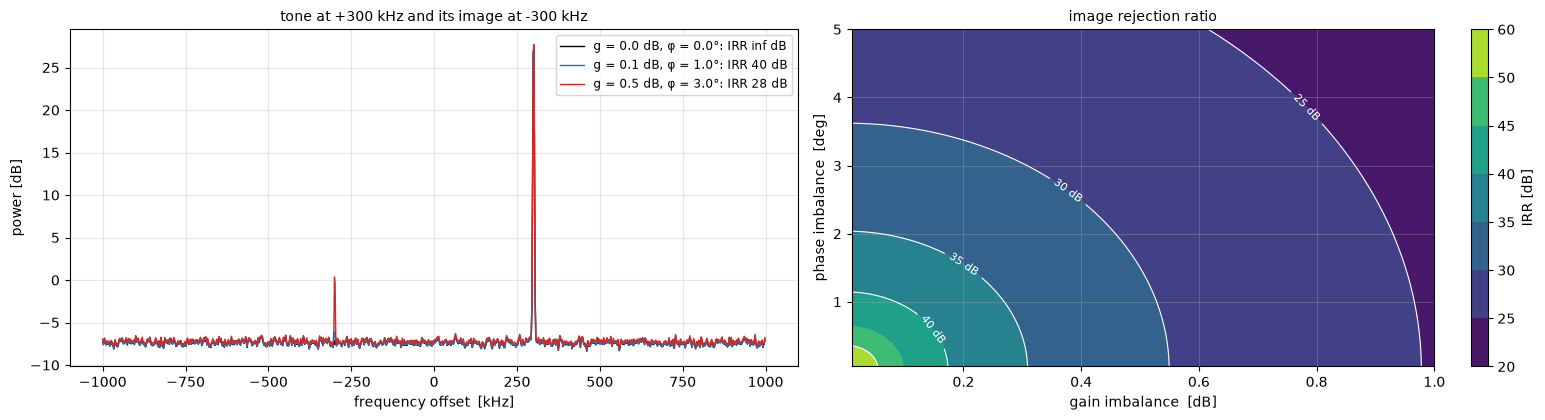

two independent noise channels with a common DC offset of 0.05 (amplitude): coherence centre channel 0.095, other channels 0.014 (noise level 0.016)


In [4]:
fsb, nb = 2e6, 2 ** 18
tb = np.arange(nb) / fsb
tone = np.exp(2j * np.pi * 300e3 * tb) + 0.3 * (rng.standard_normal(nb) + 1j * rng.standard_normal(nb))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.3))
for gdb, ph, col in ((0.0, 0.0, "k"), (0.1, 1.0, "C0"), (0.5, 3.0, "C3")):
    f, p = spectrum_db(iq_imbalance(tone, gdb, ph), fsb, 1024)
    axes[0].plot(f / 1e3, p, lw=1, color=col, label=f"g = {gdb} dB, φ = {ph}°: IRR {image_rejection_db(gdb, ph):.0f} dB")
axes[0].set(xlabel="frequency offset  [kHz]", ylabel="power [dB]", title="tone at +300 kHz and its image at -300 kHz")
axes[0].legend(fontsize=8.5)
G, P = np.meshgrid(np.linspace(0.01, 1.0, 120), np.linspace(0.05, 5.0, 120))
irr = np.vectorize(image_rejection_db)(G, P)
cs = axes[1].contourf(G, P, irr, levels=[20, 25, 30, 35, 40, 45, 50, 60], cmap="viridis")
axes[1].clabel(axes[1].contour(G, P, irr, levels=[25, 30, 35, 40, 50], colors="w", linewidths=0.8), fmt="%d dB", fontsize=8)
axes[1].set(xlabel="gain imbalance  [dB]", ylabel="phase imbalance  [deg]", title="image rejection ratio")
fig.colorbar(cs, ax=axes[1], label="IRR [dB]")
for ax in axes: ax.grid(alpha=0.3); ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()
# common DC offset in two channels -> false correlation in the centre channel
common_dc = 0.05 * np.exp(1j * 0.7)
a = (rng.standard_normal(nb) + 1j * rng.standard_normal(nb)) / np.sqrt(2) + common_dc
b = (rng.standard_normal(nb) + 1j * rng.standard_normal(nb)) / np.sqrt(2) + common_dc
acc = Accumulator.create(64, "hann"); acc.add(a, b)
coh = acc.coherence()
print(f"two independent noise channels with a common DC offset of {abs(common_dc):.2f} (amplitude): coherence centre channel "
      f"{coh[32]:.3f}, other channels {np.median(np.delete(coh, 32)):.3f} (noise level {1 / np.sqrt(acc.n_win):.3f})")

## 4. The band edges

The anti-aliasing filters (analogue and the digital decimation filters of the AD9361/FPGA) are not rectangular: the response falls off towards $\pm f_s/2$, and what is left beyond the edge is aliased back in. With the bandwidth set equal to the sample rate (the B210 profile: 2 MHz at 2 MS/s), the outer channels of the FX correlator carry less signal and some aliased noise. Practical rule: use the inner ~80 % of the channels, or sample faster than the band of interest. Simulated: white noise through a filter with a transition band, decimated to $f_s$.

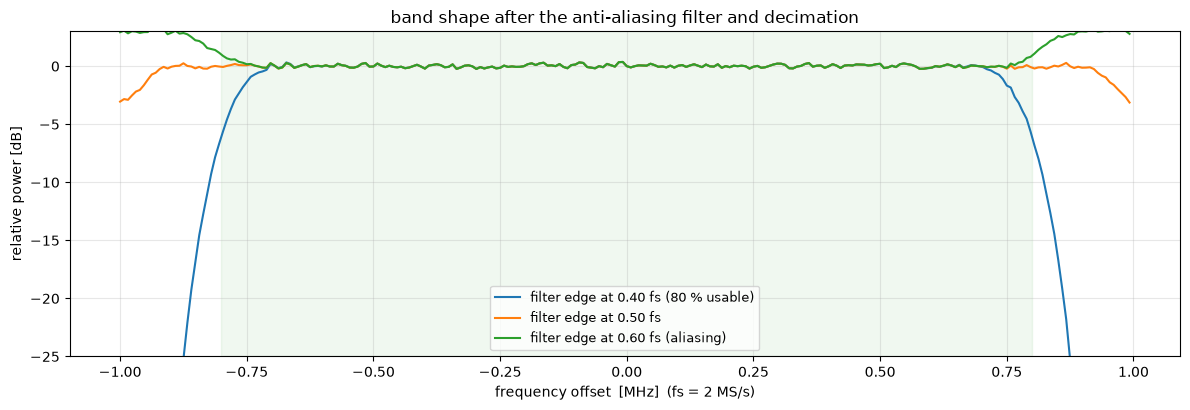

In [5]:
over = 8
wide = (rng.standard_normal(nb * over) + 1j * rng.standard_normal(nb * over)) / np.sqrt(2)
fig, ax = plt.subplots(figsize=(12, 4.2))
for cut, lab in ((0.40, "filter edge at 0.40 fs (80 % usable)"), (0.50, "filter edge at 0.50 fs"), (0.60, "filter edge at 0.60 fs (aliasing)")):
    h = firwin(255, cut / over * 2, window="hann")             # cut in units of fs, relative to the fast rate
    y = lfilter(h, 1.0, wide)[::over]
    f, p = spectrum_db(y, fsb, 256)
    ax.plot(f / 1e6, p - p[128], lw=1.5, label=lab)
ax.axvspan(-0.8, 0.8, color="C2", alpha=0.07)                 # inner 80 % of the band
ax.set(xlabel="frequency offset  [MHz]  (fs = 2 MS/s)", ylabel="relative power [dB]", ylim=(-25, 3),
       title="band shape after the anti-aliasing filter and decimation")
ax.grid(alpha=0.3); ax.legend(fontsize=9); fig.tight_layout(); plt.show()

## 5. Quantisation: how many bits?

The signal of a radio telescope is noise; the information sits in a tiny **correlation** between two noise streams ($\rho \approx 10^{-3}$ for the masers, 0.1 for the Sun with horns). A noise signal has no fine structure worth keeping – the quantiser only has to preserve the statistics well enough that the correlation survives. For weak correlations the quantised correlation is $\rho_q = \eta_Q\,\rho$ with the **quantisation efficiency**

$$\eta_Q = \frac{\left[\sum_k y_k\,\big(\phi(t_k) - \phi(t_{k+1})\big)\right]^2}{\sum_k y_k^2\,\big(\Phi(t_{k+1}) - \Phi(t_k)\big)}$$

($t_k$ thresholds, $y_k$ output levels in units of σ, $\phi$/$\Phi$ the normal density/distribution). It enters the sensitivity like a loss of collecting area: the integration time for a given S/N grows by $1/\eta_Q^2$. The data volume grows linearly with the number of bits. Checked against the package quantiser with two correlated noise streams ($\rho = 0.05$, $2^{20}$ samples):

In [6]:
n5, rho = 2 ** 20, 0.05
s = (rng.standard_normal(n5) + 1j * rng.standard_normal(n5)) / np.sqrt(2)
def noisy():
    return np.sqrt(rho) * s + np.sqrt(1 - rho) * (rng.standard_normal(n5) + 1j * rng.standard_normal(n5)) / np.sqrt(2)
a, b = noisy(), noisy()
def corr(x, y):
    return float(np.real(np.mean(x * np.conj(y)) / np.sqrt(np.mean(np.abs(x) ** 2) * np.mean(np.abs(y) ** 2))))
r0 = corr(a, b)
print(f"{'bits':>4s} {'eta_Q theory':>13s} {'measured rho_q/rho':>19s} {'time factor 1/eta^2':>20s} {'data rate at 2 MS/s, 2 ch':>26s}")
for bits in (1, 2, 3, 4, 8, 12):
    eta = quantization_efficiency(bits)
    m = corr(quantize(a, bits), quantize(b, bits)) / r0
    rate = 2e6 * 2 * bits * 2 / 8 / 1e6                         # I and Q, two channels
    print(f"{bits:4d} {eta:13.4f} {m:19.3f} {1 / eta ** 2:20.2f} {rate:21.1f} MB/s")
print(f"\n(unquantised correlation of the test streams: {r0:.4f}; statistical error of the ratio ≈ {1 / np.sqrt(2 * n5) / rho:.3f})")

bits  eta_Q theory  measured rho_q/rho  time factor 1/eta^2  data rate at 2 MS/s, 2 ch
   1        0.6366               0.624                 2.47                   1.0 MB/s
   2        0.8812               0.877                 1.29                   2.0 MB/s
   3        0.9626               0.960                 1.08                   3.0 MB/s
   4        0.9885               0.988                 1.02                   4.0 MB/s
   8        0.9999               1.000                 1.00                   8.0 MB/s
  12        1.0000               1.000                 1.00                  12.0 MB/s

(unquantised correlation of the test streams: 0.0511; statistical error of the ratio ≈ 0.014)


**2 bits are the usual compromise in VLBI:** 88 % efficiency, 29 % more integration time, a quarter of the data volume of 8 bits. The B210 delivers 12 bits (host formats `sc16` or `sc8`); for the recording, a reduction to 2–4 bits costs almost nothing in sensitivity – as long as the level is right and there is no strong interference.

**The level matters.** $\eta_Q$ depends on the step in units of σ: too small a step and the quantiser saturates (only the sign survives), too large and most samples fall into the two inner levels. The package uses the optimum steps (Max 1960). An automatic gain control that changes the level during the observation changes $\eta_Q$ – and with it the amplitude scale (notebook 08: AGC off).

**Van Vleck correction.** For strong correlations the relation is no longer linear. For 1 bit the exact arcsine law holds, $\rho_q = \tfrac{2}{\pi}\arcsin\rho$; `van_vleck_1bit` inverts it.

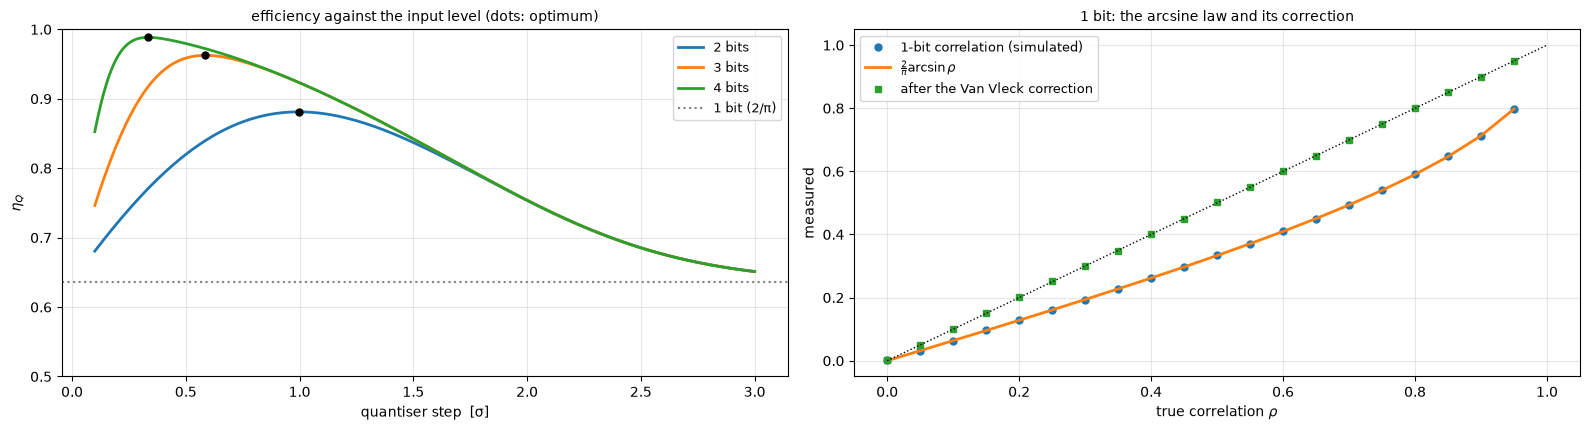

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.4))
steps = np.linspace(0.1, 3.0, 300)
for bits in (2, 3, 4):
    axes[0].plot(steps, [quantization_efficiency(bits, st) for st in steps], lw=2, label=f"{bits} bits")
    st0 = {2: 0.996, 3: 0.586, 4: 0.335}[bits]
    axes[0].plot(st0, quantization_efficiency(bits), "ko", ms=5)
axes[0].axhline(2 / np.pi, color="0.5", ls=":", label="1 bit (2/π)")
axes[0].set(xlabel="quantiser step  [σ]", ylabel=r"$\eta_Q$", ylim=(0.5, 1.0), title="efficiency against the input level (dots: optimum)")
axes[0].legend(fontsize=9)
rhos = np.linspace(0, 0.95, 20)
meas = []
for r_ in rhos:
    x = (rng.standard_normal(200_000) + 1j * rng.standard_normal(200_000)) / np.sqrt(2)
    y = np.sqrt(r_) * x + np.sqrt(1 - r_) * (rng.standard_normal(200_000) + 1j * rng.standard_normal(200_000)) / np.sqrt(2)
    xx = np.sqrt(r_) * x + np.sqrt(1 - r_) * (rng.standard_normal(200_000) + 1j * rng.standard_normal(200_000)) / np.sqrt(2)
    meas.append(corr(quantize(xx, 1), quantize(y, 1)))
true_r = rhos                                           # correlation of xx and y: r_ (common part sqrt(r_) each)
axes[1].plot(true_r, meas, "o", ms=5, label="1-bit correlation (simulated)")
axes[1].plot(true_r, 2 / np.pi * np.arcsin(true_r), lw=2, label=r"$\frac{2}{\pi}\arcsin\rho$")
axes[1].plot(true_r, van_vleck_1bit(np.array(meas)), "s", ms=4, label="after the Van Vleck correction")
axes[1].plot([0, 1], [0, 1], "k:", lw=1)
axes[1].set(xlabel=r"true correlation $\rho$", ylabel="measured", title="1 bit: the arcsine law and its correction"); axes[1].legend(fontsize=9)
for ax in axes: ax.grid(alpha=0.3); ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()

## 6. What the B210 delivers – and what that means here

The B210 digitises with 12 bits and sends the samples to the host as 16-bit (`sc16`) or 8-bit (`sc8`) integers. The dynamic range of the ADC, about $6.02\,b + 1.76$ dB for a full-scale sine, matters only when strong signals share the band: noise from the sky and the receiver needs a few bits, but a strong interferer (or the Sun on a 3 m dish, notebook 08) must not drive the ADC into saturation.

In [8]:
print(f"ADC {b210.adc_bits} bit: dynamic range for a full-scale sine ≈ {6.02 * b210.adc_bits + 1.76:.0f} dB; noise rms at 1/4 full scale "
      f"leaves {20 * np.log10(4):.0f} dB headroom for peaks (Gaussian 4σ)")
for fmt in ("sc16", "sc8"):
    rec = Receiver.from_toml(CFG / "receivers" / "b210.toml"); rec.sample_format = fmt; rec.rx_channels = 2
    print(f"host format {fmt}: {rec.bytes_per_sample} bytes per complex sample, two channels at 2 MS/s: "
          f"{rec.data_rate_bytes_per_s() / 1e6:.0f} MB/s = {rec.data_rate_bytes_per_s() * 3600 / 1e9:.0f} GB/h")
print(f"re-quantised to 2 bits for the archive: {2e6 * 2 * 2 * 2 / 8 / 1e6:.0f} MB/s = {2e6 * 2 * 2 * 2 / 8 * 3600 / 1e9:.1f} GB/h, "
      f"η_Q = {quantization_efficiency(2):.3f}")
print(f"\nT_A / T_sys: Sun with horns {19.3 / 120:.2f}, Sun with a 3 m dish {731 / 120:.1f} (power x {1 + 731 / 120:.1f}: "
      f"+{10 * np.log10(1 + 731 / 120):.1f} dB on the level), OH maser 70 Jy {70 * 1e-26 * 4.24 / (2 * 1.380649e-23) / 120:.1e}")

ADC 12 bit: dynamic range for a full-scale sine ≈ 74 dB; noise rms at 1/4 full scale leaves 12 dB headroom for peaks (Gaussian 4σ)
host format sc16: 4 bytes per complex sample, two channels at 2 MS/s: 16 MB/s = 58 GB/h
host format sc8: 2 bytes per complex sample, two channels at 2 MS/s: 8 MB/s = 29 GB/h
re-quantised to 2 bits for the archive: 2 MB/s = 7.2 GB/h, η_Q = 0.881

T_A / T_sys: Sun with horns 0.16, Sun with a 3 m dish 6.1 (power x 7.1: +8.5 dB on the level), OH maser 70 Jy 9.0e-04


## 7. Summary

| topic | statement | consequence for the project |
|---|---|---|
| Nyquist | real sampling unambiguous up to $f_s/2$ | the analogue filter defines the band |
| complex baseband | I + iQ keeps the sign of the frequency; bandwidth = $f_s$ | 2 MS/s → 2 MHz around the LO |
| IQ imbalance | image at −f, IRR from gain and phase error | lines and tones get mirror images |
| DC offset | spike at 0 Hz, common to channels with one LO | flag the centre channel; corrections off |
| band edges | filter roll-off and aliasing at ±$f_s/2$ | use the inner ~80 % of the channels |
| quantisation | $\eta_Q$ = 0.64 (1 bit), 0.88 (2 bits), 0.96 (3 bits) | 2 bits for recording, level must stay fixed (AGC off) |
| Van Vleck | non-linear for strong correlation | correct 1-/2-bit data for the Sun |

## 8. Selector

Tone frequency and level, IQ gain and phase error, DC offset, number of bits; *Run Interact* shows the spectrum of the complex baseband with image and DC spike, and the quantised histogram. (Needs a running kernel.)

In [9]:
import ipywidgets as widgets
from IPython.display import display

def run_iq(tone_khz, tone_db, gain_db, phase_deg, dc, bits):
    g = np.random.default_rng(7)
    m = 2 ** 17
    tt = np.arange(m) / 2e6
    x = (g.standard_normal(m) + 1j * g.standard_normal(m)) / np.sqrt(2)
    x = x + 10 ** (tone_db / 20) * np.exp(2j * np.pi * tone_khz * 1e3 * tt) + dc
    y = quantize(iq_imbalance(x, gain_db, phase_deg), bits)
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.3))
    f, p = spectrum_db(y, 2e6, 1024)
    axes[0].plot(f / 1e3, p, lw=1); axes[0].axvline(-tone_khz, color="C3", ls=":", lw=1)
    axes[0].set(xlabel="frequency offset  [kHz]", ylabel="power [dB]",
                title=f"spectrum, IRR {image_rejection_db(gain_db, phase_deg):.0f} dB (image position dotted)")
    axes[1].hist(y.real, bins=200, color="C0"); axes[1].set(xlabel="I value", ylabel="count", title=f"histogram of I after {bits}-bit quantisation")
    for ax in axes: ax.grid(alpha=0.3); ax.title.set_fontsize(10)
    fig.tight_layout(); plt.show()
    print(f"η_Q of {bits} bits (noise only): {quantization_efficiency(bits):.3f}")

display(widgets.interactive(
    run_iq, {"manual": True},
    tone_khz=widgets.FloatSlider(value=300, min=-900, max=900, step=10, description="tone [kHz]"),
    tone_db=widgets.FloatSlider(value=0, min=-30, max=20, step=1, description="tone / noise [dB]"),
    gain_db=widgets.FloatSlider(value=0.5, min=0, max=2, step=0.05, description="gain error [dB]"),
    phase_deg=widgets.FloatSlider(value=3, min=0, max=10, step=0.1, description="phase error [°]"),
    dc=widgets.FloatSlider(value=0.05, min=0, max=0.5, step=0.01, description="DC offset"),
    bits=widgets.Dropdown(options=[1, 2, 3, 4, 8, 12], value=12, description="bits"),
))

interactive(children=(FloatSlider(value=300.0, description='tone [kHz]', max=900.0, min=-900.0, step=10.0), Fl…